# Overall results

/tmp/ipykernel_219799/1783403487.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_last = df.groupby(["Benchmark", "Baseline"], as_index=False).apply(lambda x: x.iloc[-1]).reset_index(drop=True)


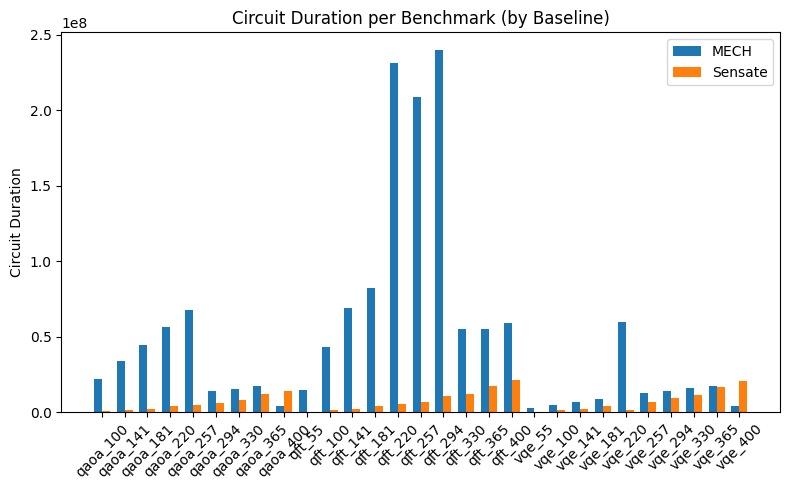

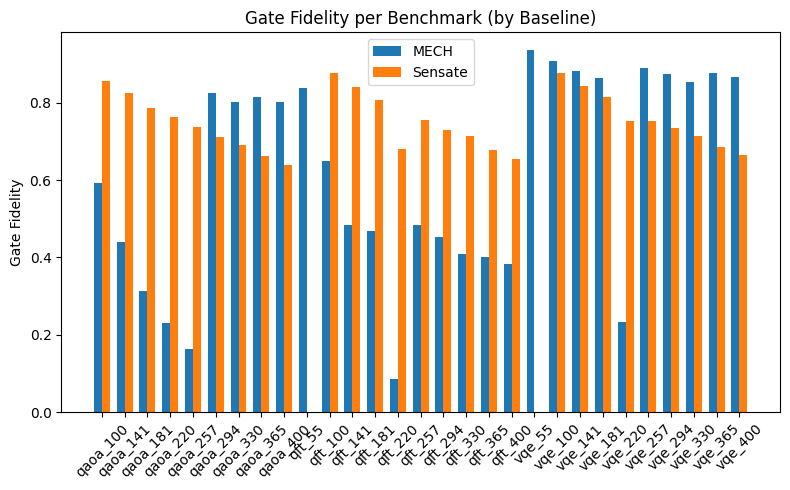

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

exp_dir = "./result/routing_scalability/benchmark"
output_path = os.path.join(exp_dir, "output.csv")
df = pd.read_csv(os.path.join(exp_dir, "output.csv"))
df["Benchmark"] = df["Algorithm"] + '_' + df["#DataQubit"].astype(str)
df_last = df.groupby(["Benchmark", "Baseline"], as_index=False).apply(lambda x: x.iloc[-1]).reset_index(drop=True)

df_last["#DataQubit"] = df_last["#DataQubit"].astype(int)
df_last["Algorithm"] = df_last["Algorithm"].astype(str)
df_last_sorted = df_last.sort_values(by=["Algorithm", "#DataQubit"])
benchmarks = df_last_sorted[["Benchmark"]].drop_duplicates()["Benchmark"].tolist()
benchmarks = [b for b in benchmarks if not b.startswith("bv")]
baselines = sorted(df_last["Baseline"].unique())
legend_dict = {"mech": "MECH", "qunoc": "Sensate"}

duration_data = {b: [] for b in baselines}
fidelity_data = {b: [] for b in baselines}

for bm in benchmarks:
    for bl in baselines:
        row = df_last[(df_last["Benchmark"] == bm) & (df_last["Baseline"] == bl)]
        if not row.empty:
            duration_data[bl].append(row["CircuitDuration"].values[0])
            fidelity_data[bl].append(row["GateFidelity"].values[0])
        else:
            duration_data[bl].append(np.nan)
            fidelity_data[bl].append(np.nan)

x = np.arange(len(benchmarks))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
for i, bl in enumerate(baselines):
    ax.bar(x + i * width, duration_data[bl], width, label=legend_dict[bl])
ax.set_ylabel("Circuit Duration")
ax.set_title("Circuit Duration per Benchmark (by Baseline)")
ax.set_xticks(x + width / 2)
ax.set_xticklabels(benchmarks, rotation=45)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join("./result/plot", "routing_scalability_benchmark_duration.svg"))
plt.savefig(os.path.join("./result/plot", "routing_scalability_benchmark_duration.pdf"))
plt.show()
plt.close()

fig, ax = plt.subplots(figsize=(8, 5))
for i, bl in enumerate(baselines):
    ax.bar(x + i * width, fidelity_data[bl], width, label=legend_dict[bl])
ax.set_ylabel("Gate Fidelity")
ax.set_title("Gate Fidelity per Benchmark (by Baseline)")
ax.set_xticks(x + width / 2)
ax.set_xticklabels(benchmarks, rotation=45)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join("./result/plot", "routing_scalability_benchmark_fidelity.svg"))
plt.savefig(os.path.join("./result/plot", "routing_scalability_benchmark_fidelity.pdf"))
plt.show()
plt.close()

# Layout Evaluation

## Scalability on package size

radial_improve:  0.017744360931869225 strip_improve:  0.014935162405189106 baseline_improve:  0.5172054957365703


/tmp/ipykernel_836758/3182693195.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby(["PackageSize", "DesignStrategy"], as_index=False).apply(lambda x: x.iloc[-1]).reset_index(drop=True)


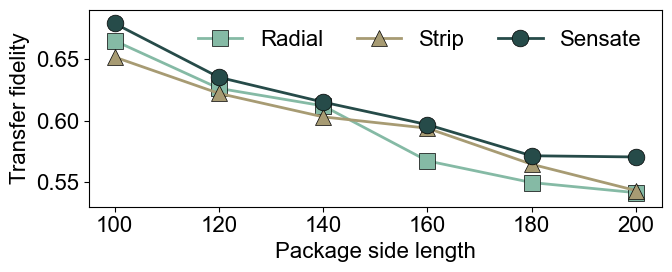

In [28]:
import os
import pandas as pd
import matplotlib.pyplot as plt

color_dict = {"heuristic": "#264B49", "radial": "#85BAA5", "strip": "#A79B73", "": "#C0C2A6", "baseline": "#4C7F79"}
plt.rcParams["font.family"] = "arial"
plt.rcParams["font.size"] = 16

exp_dir = "./result/layout_scalability/package_size"
output_path = os.path.join(exp_dir, "output.csv")
df = pd.read_csv(os.path.join(exp_dir, "output.csv"))
df = df.groupby(["PackageSize", "DesignStrategy"], as_index=False).apply(lambda x: x.iloc[-1]).reset_index(drop=True)
plt.figure(figsize=(7, 3))
design_strategies = df["DesignStrategy"].unique()
legend_dict = {"baseline": "Plain", "heuristic": "Sensate", "greedy": "Greedy Design", "rl": "RL-based Design", "strip": "Strip", "radial": "Radial"}

for design_strategy in ["baseline", "radial", "strip", "heuristic"]:
    subset = df[df["DesignStrategy"] == design_strategy]
    x = subset['PackageSize'][3:]
    y = subset['Fidelity'][3:]
    yerr = subset['FideStd'][3:]
    if design_strategy in ["heuristic"]:
        plt.plot(x, y, 
            label=legend_dict[design_strategy],
            color = color_dict[design_strategy],
            marker='o',
            markersize=12, 
            markeredgecolor="black", 
            markeredgewidth=0.5, 
            linestyle='-',
            linewidth=2
        )
        # plt.errorbar(
        #     x, y, yerr=yerr*0.4,
        #     label=legend_dict[design_strategy],
        #     color = color_dict[design_strategy],
        #     marker='o',
        #     markersize=10, 
        #     markeredgecolor="black", 
        #     markeredgewidth=0.5, 
        #     capsize=4,
        #     linestyle='-',
        #     linewidth=2
        # )
        heuristic_fide = np.array(y)
    elif design_strategy in ["baseline"]:
        baseline_fide = np.array(y)
        continue
        plt.plot(x[0], y[0], 
            label=legend_dict[design_strategy],
            color = color_dict[design_strategy],
            marker='o'
        )
    else:
        plt.plot(x, y, 
            label=legend_dict[design_strategy],
            color = color_dict[design_strategy],
            marker='s' if design_strategy == "radial" else '^',
            markersize=12, 
            markeredgecolor="black", 
            markeredgewidth=0.5, 
            linestyle='-',
            linewidth=2
        )
        if design_strategy == "radial":
            radial_fide = np.array(y)
        elif design_strategy == "strip":
            strip_fide = np.array(y)

radial_improve = (heuristic_fide - radial_fide).mean()
strip_improve = (heuristic_fide - strip_fide).mean()
baseline_improve = (heuristic_fide - baseline_fide).mean()
print("radial_improve: ", radial_improve, "strip_improve: ", strip_improve, "baseline_improve: ", baseline_improve)

# x = subset['PackageSize']
# xtick_labels = [f"{v}×{v}" for v in x]

# plt.xticks(x, xtick_labels)

plt.xlabel("Package side length")
plt.ylabel("Transfer fidelity")
# plt.title("Fidelity vs Package Size for Different Design Strategies")
# plt.grid(True, axis='y')
plt.ylim(0.53, 0.69)
plt.legend(ncol=4, loc="upper right", frameon=False, columnspacing=1.5)
plt.tight_layout()
plt.savefig(os.path.join("./result/plot", "layout_package_size.svg"), bbox_inches="tight")
plt.savefig(os.path.join("./result/plot", "layout_package_size.pdf"), bbox_inches="tight")
plt.show()
plt.close()

# Routing Evaluation

## Overall

In [211]:
algorithm_list = ["qaoa", "vqe", "qft"]
len_x = [60, 80, 100, 120, 140]

import os
import sys
sys.path.append("..")
import logging
logging.basicConfig(level=logging.WARN)
from itertools import product

from qunoc.utils.utils import get_timestamp
from qunoc.element.package import *
from qunoc.routing.circuit import Circuit

for algorithm in algorithm_list:
    depth_qunoc = []
    for size_x in len_x:
        circuit = Circuit.from_pickle(f"./result/routing_scalability/overall/{size_x}_{size_x}_{algorithm}_qunoc/qunoc_circuit.pkl")
        package = Package.from_pickle(filepath=os.path.join("./result/layout_scalability/package_size", f"{size_x}_{size_x}_greedy/package.pkl"))
        duration = circuit.estimate_duration(package)
        depth_qunoc.append(duration)
    print(f"{algorithm}_depth_qunoc =", depth_qunoc)

qaoa_depth_qunoc = [3522686.0, 8443578.0, 12243624.0, 17794003.0, 27077411.0]
vqe_depth_qunoc = [1414623.0, 2093629.0, 3056537.0, 4213893.0, 5718668.0]
qft_depth_qunoc = [6416955.0, 18116411.0, 20841125.0, 26410803.0, 51080981.0]


In [ ]:
lens=[60,80,100,120,140,160,180,200][:6]

vqe_depth_mech = [38285760, 50331000, 61594200, 69464760, 82029840, 91270680, ...][:6]
vqe_fidelity_mech = [
    0.41581906977010025,
    0.3125996563187038,
    0.2239242844550728,
    0.1675999281621799,
    0.11839605500382473,
    0.08827968126496051,
    ...
][:6]

vqe_depth_qunoc = [616298, 654487,1105762, 1520518, 1648418, 1760847, 2432293, 2718397][:6]
vqe_fidelity_qunoc = [
    0.8113873272375537,
    0.7938490308077856,
    0.7512292694458163,
    0.7300143148483073,
    0.6836135234637002,
    0.6758398941403536,
    0.6460119992622717,
    0.6249102009466331,
][:6]

qft_depth_mech = [68783040, 82189440, 135188040, 167201520,...]
qft_fidelity_mech = [0.484455281347053, 0.4685773384756661, 0.19970114113332754,...]
qft_depth_qunoc = [2206235,4267227,5737283, 6711786, 10653556, 11753601, 17591772, 21485721][:6]
qft_fidelity_qunoc = [
    0.8416262039432216,
    0.8063711052333856,
    0.7833876049639049,
    0.7541010198056735,
    0.7295256174971968,
    0.7132399252776889,
    0.6785507411075347,
    0.6547820380061532,
][:6]

qaoa_depth_mech = [32469480, 44195520, 56062920, 67946280]
qaoa_fidelity_mech = [
    0.43955178273179524,
    0.31539487855130866,
    0.22855904650713899,
    0.16167870488030922,
]
qaoa_depth_qunoc = [1364350,2200936,3728732, 5012811, 6290511, 7730954, 11927318, 14443968][:6]
qaoa_fidelity_qunoc = [
    0.8269925186864168,
    0.7866467861664668,
    0.762966250867519,
    0.7357428585987981,
    0.7109562108097198,
    0.6889347487790656,
    0.6630248406147695,
    0.6389314174903564,
][:6]


In [28]:
import csv
size_dict = {100: 40, 141: 60, 181: 80, 220: 100, 257: 120}

fide_improve = []
duration_speedup = []

with open("./main_exp.csv", "r", newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        # 转换成 float
        algo   = row['Algorithm'].upper()
        nq     = int(row['#DataQubit'])
        size   = size_dict[nq]
        prop   = float(row['QuNoCProportion'])
        mech_f = float(row['MECHGateFidelity'])
        qunoc_f= float(row['QuNoCGateFidelity'])
        improv = float(row['Improvement'])
        fide_improve.append(improv)
        mech_d = float(row['MECHCircuitDuration'])
        qunoc_d= float(row['QuNoCCircuitDuration'])
        speed  = float(row['Speedup'])
        duration_speedup.append(speed)

        print(f"{algo}-{nq} & "
              f"{size}$\\times${size} & "
              f"{prop*100:.2f}\\% & "
              f"{mech_f*100:.2f}\\% & "
              f"{qunoc_f*100:.2f}\\% & "
              f"{improv:.2f}$\\times$ & "
              f"{mech_d:.2f} & "
              f"{qunoc_d:.2f} & "
              f"{speed:.2f}$\\times$ \\\\")

import numpy as np
print("fide", np.array(fide_improve).mean(), "duration", np.array(duration_speedup).mean())

VQE-100 & 40$\times$40 & 19.00\% & 56.07\% & 84.65\% & 1.51$\times$ & 10.90 & 0.74 & 14.76$\times$ \\
VQE-141 & 60$\times$60 & 19.00\% & 41.58\% & 81.14\% & 1.95$\times$ & 15.36 & 1.41 & 10.86$\times$ \\
VQE-181 & 80$\times$80 & 12.41\% & 31.26\% & 79.38\% & 2.54$\times$ & 20.20 & 2.09 & 9.65$\times$ \\
VQE-220 & 100$\times$100 & 11.90\% & 22.39\% & 75.12\% & 3.35$\times$ & 24.72 & 3.06 & 8.09$\times$ \\
VQE-257 & 120$\times$120 & 17.49\% & 16.76\% & 73.00\% & 4.36$\times$ & 27.88 & 4.21 & 6.62$\times$ \\
QFT-100 & 40$\times$40 & 19.00\% & 64.81\% & 87.67\% & 1.35$\times$ & 17.22 & 2.63 & 6.55$\times$ \\
QFT-141 & 60$\times$60 & 19.00\% & 48.45\% & 84.16\% & 1.74$\times$ & 27.60 & 6.42 & 4.30$\times$ \\
QFT-181 & 80$\times$80 & 12.41\% & 46.86\% & 80.64\% & 1.72$\times$ & 32.98 & 18.12 & 1.82$\times$ \\
QFT-220 & 100$\times$100 & 11.90\% & 28.02\% & 78.34\% & 2.80$\times$ & 54.25 & 20.84 & 2.60$\times$ \\
QFT-257 & 120$\times$120 & 17.49\% & 19.97\% & 75.41\% & 3.78$\times$ & 67.10 & 2

## Ablation study

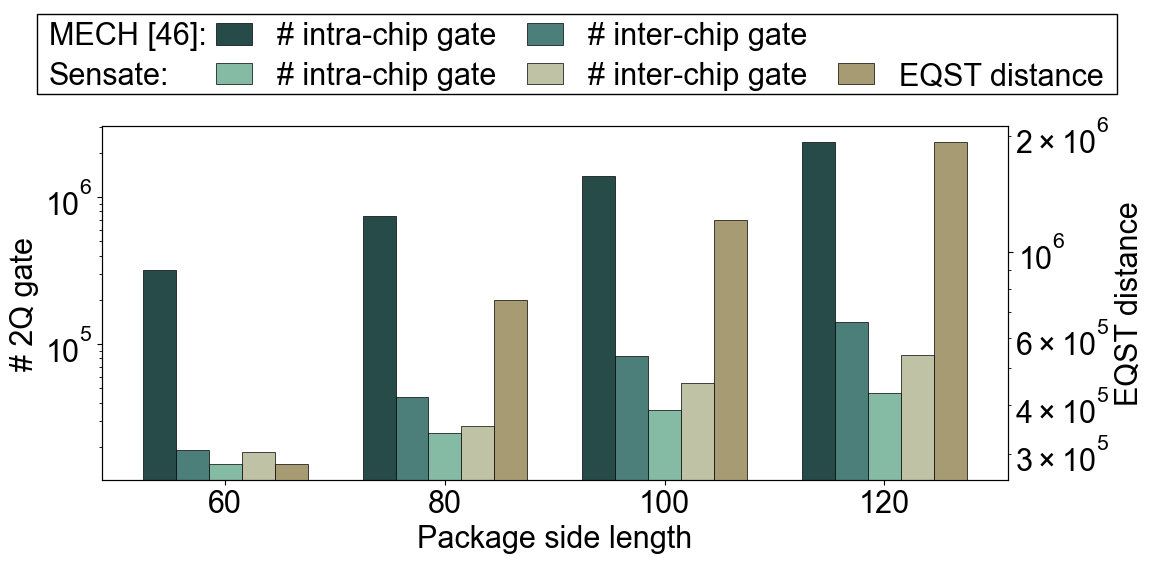

0.9682095909002575
0.2864508947796087


In [22]:
import os
import json
import numpy as np

algorithm = "qaoa"
package_size = list(range(60, 140, 20))

intra_num_mech = []
inter_num_mech = []
intra_num_qunoc = []
inter_num_qunoc = []
qst_dist_qunoc = []

for size in package_size:
    mech_result_path = f"./result/routing_scalability/overall/{size}_{size}_{algorithm}_mech/exp_result.json"
    qunoc_result_path = f"./result/routing_scalability/overall/{size}_{size}_{algorithm}_qunoc/exp_result.json"
    
    with open(mech_result_path, "r") as f:
        mech_exp_result = json.load(f)
        intra_num_mech.append(mech_exp_result.get("on_chip"))
        inter_num_mech.append(mech_exp_result.get("cross_chip"))

    with open(qunoc_result_path, "r") as f:
        qunoc_exp_result = json.load(f)
        intra_num_qunoc.append(qunoc_exp_result.get("intra_gate"))
        inter_num_qunoc.append(qunoc_exp_result.get("inter_gate"))
        qst_dist_qunoc.append(qunoc_exp_result.get("qst_dist"))

intra_num_mech = np.array(intra_num_mech)
inter_num_mech = np.array(inter_num_mech)
intra_num_qunoc = np.array(intra_num_qunoc)
inter_num_qunoc = np.array(inter_num_qunoc)
qst_dist_qunoc = np.array(qst_dist_qunoc)

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerTuple

color_list = ["#264B49", "#4C7F79", "#85BAA5", "#C0C2A6", "#A79B73"]
plt.rcParams["font.family"] = "arial"
plt.rcParams["font.size"] = 22

bar_width = 0.15
x = np.arange(len(package_size))

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

# --- 左轴：门操作数量 ---
b1 = ax1.bar(x - 2*bar_width, intra_num_mech, width=bar_width, color=color_list[0], edgecolor="black", linewidth=0.5)
b2 = ax1.bar(x - bar_width, inter_num_mech, width=bar_width, color=color_list[1], edgecolor="black", linewidth=0.5)
b3 = ax1.bar(x, intra_num_qunoc, width=bar_width, color=color_list[2], edgecolor="black", linewidth=0.5)
b4 = ax1.bar(x + bar_width, inter_num_qunoc, width=bar_width, color=color_list[3], edgecolor="black", linewidth=0.5)

# --- 右轴：QST dist ---
b5 = ax2.bar(x + 2*bar_width, qst_dist_qunoc, width=bar_width, color=color_list[4], edgecolor="black", linewidth=0.5)

# --- 坐标轴设置 ---
ax1.set_xlabel("Package side length")
ax1.set_ylabel("# 2Q gate")
ax2.set_ylabel("EQST distance")
ax1.set_yscale("log")
ax2.set_yscale("log")

ax1.set_xticks(x)
ax1.set_xticklabels([f"{s}" for s in package_size])
# ax1.set_xticklabels([f"{s}×{s}" for s in package_size], rotation=30)

# --- 图例（合并 ax1 和 ax2） ---
mech_intra_patch = mpatches.Patch(facecolor=color_list[0], label="# intra-chip gate", edgecolor="black", linewidth=0.5)
mech_inter_patch = mpatches.Patch(facecolor=color_list[1], label="# inter-chip gate", edgecolor="black", linewidth=0.5)

qunoc_intra_patch = mpatches.Patch(facecolor=color_list[2], label="# intra-chip gate", edgecolor="black", linewidth=0.5)
qunoc_inter_patch = mpatches.Patch(facecolor=color_list[3], label="# inter-chip gate", edgecolor="black", linewidth=0.5)
qst_patch        = mpatches.Patch(facecolor=color_list[4], label="EQST distance", edgecolor="black", linewidth=0.5)

# 位置参数（自己调）
text_w  = 0.06
legend_w = 0.176
legend_h_mech    = 1.10
legend_h_sensate = 1.02

# 写“组名”文本
rect = mpatches.Rectangle(
    (0.05, 0.984),  # 左下角位置 (相对于 figure 坐标 0~1)
    width=0.9,    # 宽度
    height=0.16,  # 高度
    transform=fig.transFigure,  # 用 figure 的坐标系
    fill=False,                # 只画边框
    color="black",             # 边框颜色
    linewidth=1.0,             # 线宽
)
fig.patches.append(rect)
fig.text(text_w, legend_h_mech, "MECH [46]:", ha="left", va="center")
fig.text(text_w, legend_h_sensate, "Sensate:", ha="left", va="center")

# MECH 组 legend
fig.legend(
    handles=[mech_intra_patch, mech_inter_patch],
    labels=[h.get_label() for h in [mech_intra_patch, mech_inter_patch]],
    handlelength=1.2,
    ncol=2,
    columnspacing=1.,
    loc="center left",
    bbox_to_anchor=(legend_w, legend_h_mech),
    frameon=False
)

# Sensate 组 legend
fig.legend(
    handles=[qunoc_intra_patch, qunoc_inter_patch, qst_patch],
    labels=[h.get_label() for h in [qunoc_intra_patch, qunoc_inter_patch, qst_patch]],
    handlelength=1.2,
    ncol=3,
    columnspacing=1.,
    loc="center left",
    bbox_to_anchor=(legend_w, legend_h_sensate),
    frameon=False
)

# plt.title(f"Compilation results ({algorithm.upper()})")
plt.tight_layout()
plt.savefig(os.path.join("./result/plot", "route_op_break.svg"), bbox_inches="tight")
plt.savefig(os.path.join("./result/plot", "route_op_break.pdf"), bbox_inches="tight")
plt.show()

print(((intra_num_mech - intra_num_qunoc) / intra_num_mech).mean())
print(((inter_num_mech - inter_num_qunoc) / inter_num_mech).mean())

## Package shape

In [210]:
algorithm_list = ["qaoa", "vqe", "qft"]
len_x = [10, 20, 40, 50, 80, 100]

import os
import sys
sys.path.append("..")
import logging
logging.basicConfig(level=logging.WARN)
from itertools import product

from qunoc.utils.utils import get_timestamp
from qunoc.element.package import *
from qunoc.routing.circuit import Circuit

for algorithm in algorithm_list:
    depth_qunoc = []
    for size_x in len_x:
        circuit = Circuit.from_pickle(f"./result/routing_scalability/benchmark/{size_x}_{10000//size_x}_{algorithm}_qunoc/qunoc_circuit.pkl")
        package = Package.from_pickle(filepath=os.path.join("./result/layout_scalability/package_shape", f"{size_x}_{10000//size_x}_greedy/package.pkl"))
        duration = circuit.estimate_duration(package)
        depth_qunoc.append(duration)
    print(f"{algorithm}_depth_qunoc =", depth_qunoc)

qaoa depth qunoc:  [38696993.0, 21632194.0, 14810192.0, 15010202.0, 12230461.0, 12390100.0]
vqe depth qunoc:  [9817122.0, 5371348.0, 3756015.0, 3554823.0, 3158316.0, 3138387.0]
qft depth qunoc:  [37857793.0, 28066194.0, 24045582.0, 25575022.0, 22617419.0, 21519547.0]


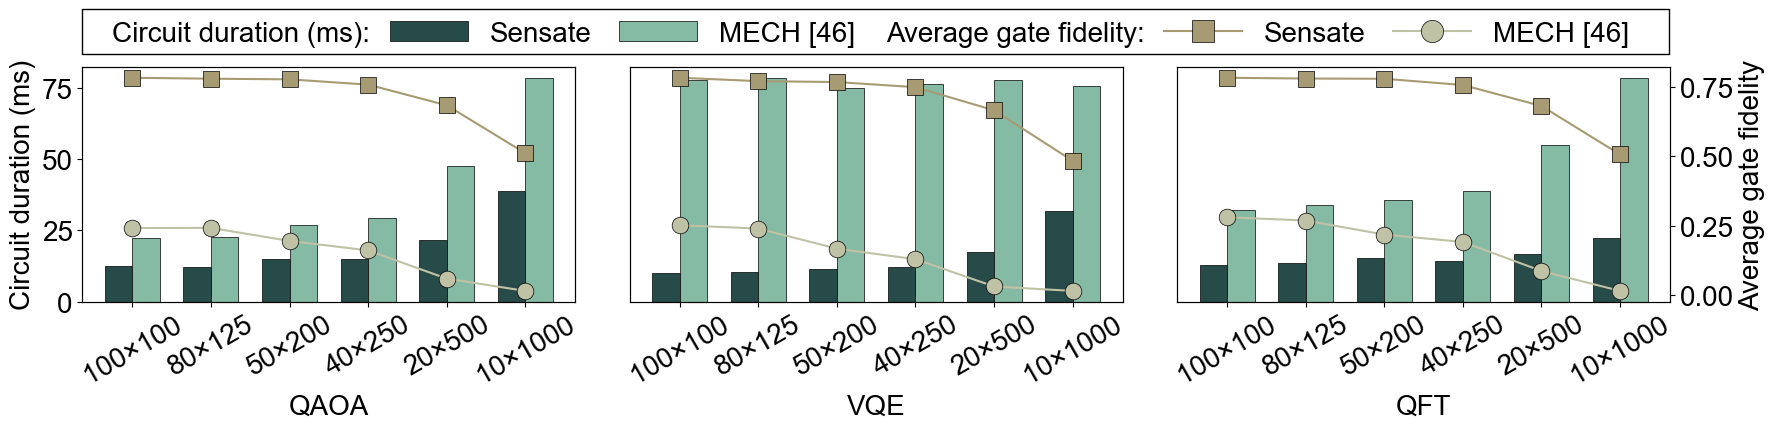

0.26864585583564227


In [21]:
len_x = [10, 20, 40, 50, 80,100]

qaoa_depth_mech = [195386880, 118687680, 72985080, 66856440, 56626080, 55543080]
qaoa_fidelity_mech = [
    0.005445557382451204,
    0.04926703255408567,
    0.14967754511727974,
    0.18347918576355624,
    0.2298441916408752,
    0.22940774047639015,
]
qaoa_depth_qunoc = [7225100, 4575327, 4019725, 4126585, 3125052, 3804733]
qaoa_fidelity_qunoc = [
    0.495699773192144,
    0.6663211612557907,
    0.7398982578345757,
    0.7587011207223631,
    0.761022887323133,
    0.7643456290277862,
]

vqe_depth_mech = [58388520, 60032400, 58792080, 57738720, 60420000, 60052920]
vqe_fidelity_mech = [
    0.00047192659979136887,
    0.016180503355549103,
    0.11260755781429949,
    0.1497315013567595,
    0.22083011371695704,
    0.2325856237902931,
]
vqe_depth_qunoc = [2087482, 1449598, 1321940, 1166298, 980924, 1153262]
vqe_fidelity_qunoc = [
    0.45992284360336855,
    0.6385096780890347,
    0.7202226732041086,
    0.7383549040504628,
    0.7415849326782247,
    0.7534768052491286,
]

qft_depth_mech = [329920560, 231319680, 163913760, 150495960, 142301640, 135188040]
qft_fidelity_mech = [
    0.014715553557782226,
    0.08664035323177288,
    0.19128338141733733,
    0.21787653945678256,
    0.2685913393190123,
    0.2802163585184626,
]
qft_depth_qunoc = [6756476, 5536269, 5887790, 6344355, 5135802, 5953605]
qft_fidelity_qunoc = [
    0.5067037540264009,
    0.68159087777312,
    0.7571455611159814,
    0.7797169046674786,
    0.780478609294714,
    0.7832629394497482,
]

qaoa_depth_qunoc = [38696993.0, 21632194.0, 14810192.0, 15010202.0, 12230461.0, 12390100.0]
vqe_depth_qunoc = [9817122.0, 5371348.0, 3756015.0, 3554823.0, 3158316.0, 3138387.0]
qft_depth_qunoc = [37857793.0, 28066194.0, 24045582.0, 25575022.0, 22617419.0, 21519547.0]

def to_ms(lst, modify_const=1): 
    return [x / 1000000 * modify_const for x in lst]

import sys
sys.path.append("..")
from baseline.utils.utils import duration_modify_const
qaoa_depth_mech = to_ms(qaoa_depth_mech, duration_modify_const)[::-1]
qaoa_depth_qunoc = to_ms(qaoa_depth_qunoc)[::-1]
vqe_depth_mech = to_ms(vqe_depth_mech, duration_modify_const)[::-1]
vqe_depth_qunoc = to_ms(vqe_depth_qunoc)[::-1]
qft_depth_mech = to_ms(qft_depth_mech, duration_modify_const)[::-1]
qft_depth_qunoc = to_ms(qft_depth_qunoc)[::-1]

len_x = len_x[::-1]
qaoa_fidelity_mech = qaoa_fidelity_mech[::-1]
qaoa_fidelity_qunoc = qaoa_fidelity_qunoc[::-1]
vqe_fidelity_mech = vqe_fidelity_mech[::-1]
vqe_fidelity_qunoc = vqe_fidelity_qunoc[::-1]
qft_fidelity_mech = qft_fidelity_mech[::-1]
qft_fidelity_qunoc = qft_fidelity_qunoc[::-1]

datasets = [
    ("QAOA", qaoa_depth_mech, qaoa_depth_qunoc, qaoa_fidelity_mech, qaoa_fidelity_qunoc),
    ("VQE", vqe_depth_mech, vqe_depth_qunoc, vqe_fidelity_mech, vqe_fidelity_qunoc),
    ("QFT", qft_depth_mech, qft_depth_qunoc, qft_fidelity_mech, qft_fidelity_qunoc),
]

import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.legend_handler import HandlerTuple


color_list = ["#264B49", "#4C7F79", "#85BAA5", "#C0C2A6", "#A79B73"]
plt.rcParams["font.family"] = "arial"
plt.rcParams["font.size"] = 20

bar_width = 0.35
index = range(len(len_x))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharex=True)

for i, (ax, (title, depth_mech, depth_qunoc, fide_mech, fide_qunoc)) in enumerate(zip(axes, datasets)):
    ax2 = ax.twinx()

    # 深度柱状图，左侧y轴
    ax.bar([j - bar_width / 2 for j in index], depth_qunoc, bar_width, color=color_list[0], edgecolor="black", linewidth=0.5)
    ax.bar([j + bar_width / 2 for j in index], depth_mech, bar_width, color=color_list[2], edgecolor="black", linewidth=0.5)
    ax.set_ylabel("Circuit duration (ms)")
    ax.tick_params(axis="y")

    # 保真度折线图，右侧y轴
    ax2.plot(index, fide_qunoc, "s-", markersize=12, markeredgecolor="black", markeredgewidth=0.5, color=color_list[4])
    ax2.plot(index, fide_mech, "o-", markersize=12, markeredgecolor="black", markeredgewidth=0.5, color=color_list[3])
    ax2.set_ylabel("Average gate fidelity")
    ax2.tick_params(axis="y")

    # X轴设置
    ax.set_xticks(index)
    ax.set_xticklabels([f"{x}×{10000//x}" for x in len_x], rotation=30)
    ax.set_xlabel(title)

    # 标题
    # ax.set_title(title)

    # 控制y轴刻度显示
    if i == 0:
        # 最左边子图，显示左y轴（深度）刻度，隐藏右y轴刻度
        ax.yaxis.set_visible(True)
        ax2.yaxis.set_visible(False)
    elif i == 2:
        # 最右边子图，隐藏左y轴刻度，显示右y轴（保真度）刻度
        ax.yaxis.set_visible(False)
        ax2.yaxis.set_visible(True)
    else:
        # 中间子图，两侧y轴刻度都隐藏
        ax.yaxis.set_visible(False)
        ax2.yaxis.set_visible(False)

text_h = 0.925
legend_h = 1.01
duration_text_w  = 0.145
duration_legend_w = 0.357
fidelity_text_w  = 0.575
fidelity_legend_w = 0.787

rect = mpatches.Rectangle(
    (0.0565, 0.88),  # 左下角位置 (相对于 figure 坐标 0~1)
    width=0.882,    # 宽度
    height=0.1,  # 高度
    transform=fig.transFigure,  # 用 figure 的坐标系
    fill=False,                # 只画边框
    color="black",             # 边框颜色
    linewidth=1.0,             # 线宽
)
fig.patches.append(rect)
fig.text(duration_text_w, text_h, "Circuit duration (ms):", ha="center", va="center")
fig.text(fidelity_text_w, text_h, "Average gate fidelity:", ha="center", va="center")

qunoc_patch = mpatches.Patch(facecolor=color_list[0], edgecolor="black", linewidth=0.5)
qunoc_line = mlines.Line2D([], [], color=color_list[4], marker='s', linestyle='-', markersize=10, markeredgecolor="black", markeredgewidth=0.5)
mech_patch = mpatches.Patch(facecolor=color_list[2], edgecolor="black", linewidth=0.5)
mech_line = mlines.Line2D([], [], color=color_list[3], marker='o', linestyle='-', markersize=10, markeredgecolor="black", markeredgewidth=0.5)

handles = [(qunoc_patch, qunoc_line), (mech_patch, mech_line)]
labels = ["Sensate", "MECH[3]"]

fig.legend(
    [qunoc_patch, mech_patch], ["Sensate", "MECH [46]"],
    handler_map={tuple: HandlerTuple(ndivide=None, pad=1.5)},
    loc="upper center",
    bbox_to_anchor=(duration_legend_w, legend_h),
    ncol=2,
    frameon=False,
    markerscale=1.6, 
    handlelength=2.8,   # 线段长度
    handletextpad=0.8,  # 线段和文字之间的间距
    columnspacing=1.,   # 列间距
)

fig.legend(
    [qunoc_line, mech_line], ["Sensate", "MECH [46]"],
    handler_map={tuple: HandlerTuple(ndivide=None, pad=1.5)},
    loc="upper center",
    bbox_to_anchor=(fidelity_legend_w, legend_h),
    ncol=2,
    frameon=False,
    markerscale=1.6, 
    handlelength=2.8,   # 线段长度
    handletextpad=0.8,  # 线段和文字之间的间距
    columnspacing=1.,   # 列间距
)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(os.path.join("./result/plot", "route_package_shape.svg"), bbox_inches="tight")
plt.savefig(os.path.join("./result/plot", "route_package_shape.pdf"), bbox_inches="tight")
plt.show()
plt.close()

print(qaoa_fidelity_qunoc[0] - qaoa_fidelity_qunoc[-1])

## Geometry

In [ ]:
algorithm_list = ["qaoa", "vqe", "qft"]
chiplet_topologys = ["square","hexagon","heavy_square","heavy_hexagon"]

import os
import sys
sys.path.append("..")
import logging
logging.basicConfig(level=logging.WARN)
from itertools import product

from qunoc.utils.utils import get_timestamp
from qunoc.element.package import *
from qunoc.routing.circuit import Circuit

for algorithm in algorithm_list:
    depth_qunoc = []
    for topology in chiplet_topologys:
        circuit = Circuit.from_pickle(f"./result/routing_scalability/geometry/{topology}_{algorithm}_qunoc/qunoc_circuit.pkl")
        package = Package.from_pickle(filepath=os.path.join("./result/layout_scalability/geometry", f"{topology}_greedy/package.pkl"))
        duration = circuit.estimate_duration(package)
        depth_qunoc.append(duration)
    print(f"{algorithm}_depth_qunoc =", depth_qunoc)

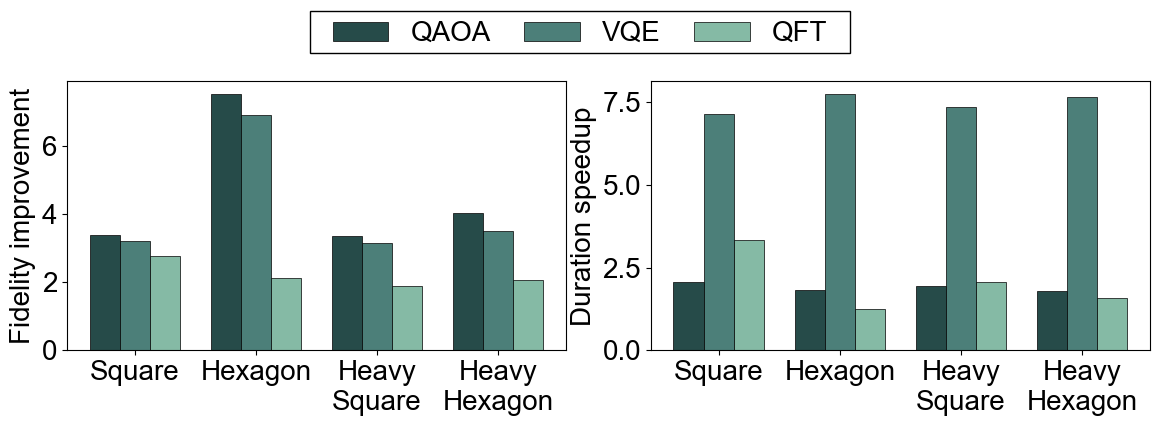

Average fide improve 3.6611998592696104
Average fide improve 3.8096379421574036


In [1]:
chiplet_topology = ["Square","Hexagon","Heavy\nSquare","Heavy\nHexagon"]

qaoa_depth_mech = [58194720, 54813480, 55948920, 56320560]
qaoa_fidelity_mech = [
    0.22606662829417537,
    0.10176864307202294,
    0.22923063326844978,
    0.18974802817370423,
]
qaoa_depth_qunoc = [3678755, 3870084, 3851238, 4100301]
qaoa_fidelity_qunoc = [
    0.7630219513224215,
    0.7654861647863771,
    0.7707741908680378,
    0.7643655112135681,
]

vqe_depth_mech = [61420920, 62016000, 59865960, 59909280]
vqe_fidelity_mech = [
    0.23128587252727104,
    0.10826300382242597,
    0.23824386919285606,
    0.21381790975364842,
]
vqe_depth_qunoc = [1383919, 1198760, 1345919, 1186929]
vqe_fidelity_qunoc = [
    0.7425498472321272,
    0.7485626635476867,
    0.7493720721091658,
    0.7517020602357094,
]

qft_depth_mech = [135188040, 65529480, 89236920, 82937280]
qft_fidelity_mech = [
    0.2802163585184626,
    0.3675913251186427,
    0.4175582566605039,
    0.3783069177979652,
]
qft_depth_qunoc = [4854328, 5888996, 5352431, 6087974]
qft_fidelity_qunoc = [
    0.7796840557072211,
    0.782818962512848,
    0.785746502473944,
    0.781948954456533,
]

qaoa_depth_qunoc = [11327330.0, 12060698.0, 11505988.0, 12556992.0]
vqe_depth_qunoc = [3450419.0, 3217949.0, 3269219.0, 3145346.0]
qft_depth_qunoc = [16338328.0, 21008667.0, 17489356.0, 20961753.0]

import os
import numpy as np

def to_ms(lst, modify_const=1): 
    return [x / 1000000 * modify_const for x in lst]

import sys
sys.path.append("..")
from baseline.utils.utils import duration_modify_const
qaoa_depth_mech = to_ms(qaoa_depth_mech, duration_modify_const)
qaoa_depth_qunoc = to_ms(qaoa_depth_qunoc)
vqe_depth_mech = to_ms(vqe_depth_mech, duration_modify_const)
vqe_depth_qunoc = to_ms(vqe_depth_qunoc)
qft_depth_mech = to_ms(qft_depth_mech, duration_modify_const)
qft_depth_qunoc = to_ms(qft_depth_qunoc)

fide_improve_qaoa = np.array(qaoa_fidelity_qunoc) / np.array(qaoa_fidelity_mech)
fide_improve_vqe  = np.array(vqe_fidelity_qunoc) / np.array(vqe_fidelity_mech)
fide_improve_qft  = np.array(qft_fidelity_qunoc) / np.array(qft_fidelity_mech)

speedup_qaoa = np.array(qaoa_depth_mech) / np.array(qaoa_depth_qunoc)
speedup_vqe  = np.array(vqe_depth_mech)  / np.array(vqe_depth_qunoc)
speedup_qft  = np.array(qft_depth_mech)  / np.array(qft_depth_qunoc)


import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.legend_handler import HandlerTuple


color_list = ["#264B49", "#4C7F79", "#85BAA5", "#C0C2A6", "#A79B73"]
plt.rcParams["font.family"] = "arial"
plt.rcParams["font.size"] = 20

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# --- 子图1: 保真度差值 (折线图) ---
bar_width = 0.25
x = np.arange(len(chiplet_topology))

ax1.bar(x - bar_width, fide_improve_qaoa, width=bar_width, label="QAOA", color=color_list[0], edgecolor="black", linewidth=0.5)
ax1.bar(x,             fide_improve_vqe,  width=bar_width, label="VQE", color=color_list[1], edgecolor="black", linewidth=0.5)
ax1.bar(x + bar_width, fide_improve_qft,  width=bar_width, label="QFT", color=color_list[2], edgecolor="black", linewidth=0.5)

ax1.set_xticks(x)
ax1.set_xticklabels(chiplet_topology, ha="center")
# ax1.set_xlabel("Chiplet topology")
ax1.set_ylabel("Fidelity improvement")
# ax1.set_title("Fidelity optimization")
fig.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.125), frameon=False, columnspacing=1.2)

# --- 子图2: 深度加速比 (柱状图) ---
bar_width = 0.25
x = np.arange(len(chiplet_topology))

ax2.bar(x - bar_width, speedup_qaoa, width=bar_width, label="QAOA", color=color_list[0], edgecolor="black", linewidth=0.5)
ax2.bar(x,             speedup_vqe,  width=bar_width, label="VQE", color=color_list[1], edgecolor="black", linewidth=0.5)
ax2.bar(x + bar_width, speedup_qft,  width=bar_width, label="QFT", color=color_list[2], edgecolor="black", linewidth=0.5)

ax2.set_xticks(x)
ax2.set_xticklabels(chiplet_topology, ha="center")
# ax2.set_xlabel("Chiplet topology")
ax2.set_ylabel("Duration speedup")
# ax2.set_title("Depth optimization")
# ax2.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.48, 1.25), frameon=False, columnspacing=1.2)

rect = mpatches.Rectangle(
    (0.275, 0.982),  # 左下角位置 (相对于 figure 坐标 0~1)
    width=0.45,    # 宽度
    height=0.105,  # 高度
    transform=fig.transFigure,  # 用 figure 的坐标系
    fill=False,                # 只画边框
    color="black",             # 边框颜色
    linewidth=1.0,             # 线宽
)
fig.patches.append(rect)

plt.tight_layout(w_pad=1)
plt.savefig(os.path.join("./result/plot", "route_chiplet_topology.svg"), bbox_inches="tight")
plt.savefig(os.path.join("./result/plot", "route_chiplet_topology.pdf"), bbox_inches="tight")
plt.show()
plt.close()

print("Average fide improve", np.concatenate([fide_improve_qaoa, fide_improve_qft, fide_improve_vqe]).mean())
print("Average fide improve", np.concatenate([speedup_qaoa, speedup_qft, speedup_vqe]).mean())

## Chiplet size

In [214]:
algorithm_list = ["qaoa", "vqe", "qft"]
chiplet_size = [5, 10,15,20,25]

import os
import sys
sys.path.append("..")
import logging
logging.basicConfig(level=logging.WARN)
from itertools import product

from qunoc.utils.utils import get_timestamp
from qunoc.element.package import *
from qunoc.routing.circuit import Circuit

for algorithm in algorithm_list:
    depth_qunoc = []
    for size_x in chiplet_size:
        circuit = Circuit.from_pickle(f"./result/routing_scalability/chiplet_len/{size_x}_{algorithm}_qunoc/qunoc_circuit.pkl")
        package = Package.from_pickle(filepath=os.path.join("./result/layout_scalability/package_shape", f"100_100_greedy/package.pkl"))
        duration = circuit.estimate_duration(package)
        depth_qunoc.append(duration)
    print(f"{algorithm}_depth_qunoc =", depth_qunoc)

qaoa_depth_qunoc = [12603879.0, 12455374.0, 12245448.0, 12291639.0, 12366170.0]
vqe_depth_qunoc = [3096174.0, 3160916.0, 3237051.0, 3128743.0, 3145229.0]
qft_depth_qunoc = [21519547.0, 21519547.0, 21519547.0, 21519547.0, 21519547.0]


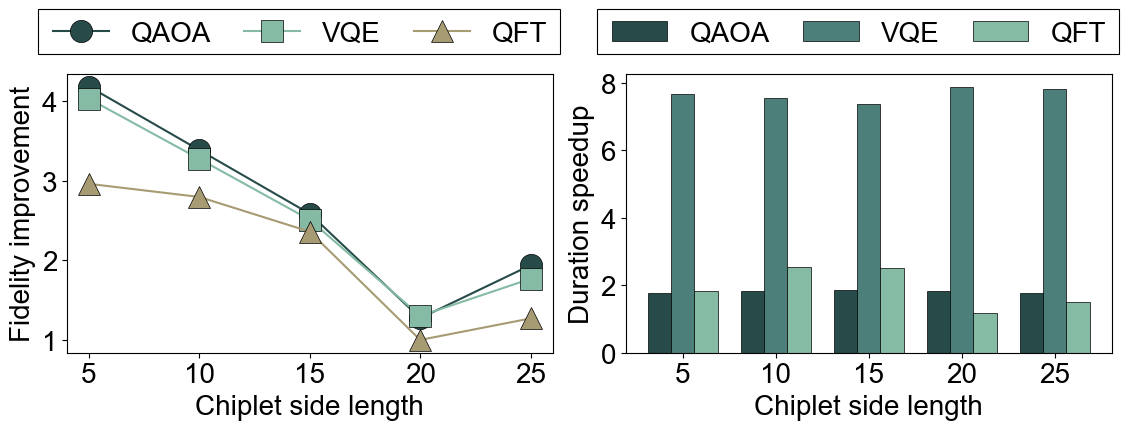

Average fide improve 2.4412425540055476
Average fide improve 3.784517655386062


In [10]:
chiplet_size = [5, 10,15,20,25]

qaoa_depth_mech = [55116720, 56400360, 56213400, 56031000, 54843120]
qaoa_fidelity_mech = [
    0.6535956822948633 ** (2 ** 2),
    0.22584072246282394,
    0.06461681876030888 ** ((10/15) ** 2),
    0.13037854042359368 ** (0.5 ** 2),
    0.002998536627765956 ** (0.4 ** 2),
]
qaoa_depth_qunoc = [3870020, 3817532, 3773606, 3773305, 3788386]
qaoa_fidelity_qunoc = [
    0.7631693808103188,
    0.7642150037448315,
    0.7647749465144752,
    0.7644413454738298,
    0.7648520674677164,
]

vqe_depth_mech = [59106720, 59453280, 59368920, 61293240, 61151880]
vqe_fidelity_mech = [
    0.6572505866750026 ** (2 ** 2),
    0.22891107767915148,
    0.06691336338383565 ** ((10/15) ** 2),
    0.11213801470795648 ** (0.5 ** 2),
    0.0048229024501589566 ** (0.4 ** 2),
]
vqe_depth_qunoc = [1121199, 1148716, 1192676, 1141918, 1156029]
vqe_fidelity_qunoc = [
    0.7517996770378899,
    0.7491307755720185,
    0.7540559518908756,
    0.7525047672122407,
    0.752746671816544,
]

qft_depth_mech = [97627320, 135188040, 134054880, 63089880, 79973280]
qft_fidelity_mech = [
    0.7905597052508171 ** (2 ** 2.5),
    0.2802163585184626,
    0.08370195453751363 ** ((10/15) ** 2),
    0.3783069177979652 ** (0.5 ** 2),
    0.049023250171306466 ** (0.4 ** 2),
]
qft_depth_qunoc = [5953605, 5953605, 5953605, 5953605, 5953605]
qft_fidelity_qunoc = [
    0.7832629394497482,
    0.7832629394497482,
    0.7832629394497482,
    0.7832629394497482,
    0.7832629394497482,
]

qaoa_depth_qunoc = [12603879.0, 12455374.0, 12245448.0, 12291639.0, 12366170.0]
vqe_depth_qunoc = [3096174.0, 3160916.0, 3237051.0, 3128743.0, 3145229.0]
qft_depth_qunoc = [21519547.0, 21519547.0, 21519547.0, 21519547.0, 21519547.0]

# chiplet_size = chiplet_size[1:]
# qaoa_depth_mech = qaoa_depth_mech[1:]
# qaoa_fidelity_mech = qaoa_fidelity_mech[1:]
# qaoa_depth_qunoc = qaoa_depth_qunoc[1:]
# qaoa_fidelity_qunoc = qaoa_fidelity_qunoc[1:]
# vqe_depth_mech = vqe_depth_mech[1:]
# vqe_fidelity_mech = vqe_fidelity_mech[1:]
# vqe_depth_qunoc = vqe_depth_qunoc[1:]
# vqe_fidelity_qunoc = vqe_fidelity_qunoc[1:]
# qft_depth_mech = qft_depth_mech[1:]
# qft_fidelity_mech = qft_fidelity_mech[1:]
# qft_depth_qunoc = qft_depth_qunoc[1:]
# qft_fidelity_qunoc = qft_fidelity_qunoc[1:]

import os
import numpy as np

def to_ms(lst, modify_const=1): 
    return [x / 1000000 * modify_const for x in lst]

import sys
sys.path.append("..")
from baseline.utils.utils import duration_modify_const
qaoa_depth_mech = to_ms(qaoa_depth_mech, duration_modify_const)
qaoa_depth_qunoc = to_ms(qaoa_depth_qunoc)
vqe_depth_mech = to_ms(vqe_depth_mech, duration_modify_const)
vqe_depth_qunoc = to_ms(vqe_depth_qunoc)
qft_depth_mech = to_ms(qft_depth_mech, duration_modify_const)
qft_depth_qunoc = to_ms(qft_depth_qunoc)

fide_improve_qaoa = np.array(qaoa_fidelity_qunoc) / (np.array(qaoa_fidelity_mech))
fide_improve_vqe  = np.array(vqe_fidelity_qunoc) / (np.array(vqe_fidelity_mech))
fide_improve_qft  = np.array(qft_fidelity_qunoc) / (np.array(qft_fidelity_mech))

speedup_qaoa = np.array(qaoa_depth_mech) / np.array(qaoa_depth_qunoc)
speedup_vqe  = np.array(vqe_depth_mech)  / np.array(vqe_depth_qunoc)
speedup_qft  = np.array(qft_depth_mech)  / np.array(qft_depth_qunoc)

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.legend_handler import HandlerTuple


color_list = ["#264B49", "#4C7F79", "#85BAA5", "#C0C2A6", "#A79B73"]
plt.rcParams["font.family"] = "arial"
plt.rcParams["font.size"] = 20

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# --- 子图1: 保真度差值 (折线图) ---
ax1.plot(chiplet_size, fide_improve_qaoa, "o-", markersize=16, markeredgecolor="black", markeredgewidth=0.5, label="QAOA", color=color_list[0])
ax1.plot(chiplet_size, fide_improve_vqe, "s-", markersize=16, markeredgecolor="black", markeredgewidth=0.5, label="VQE", color=color_list[2])
ax1.plot(chiplet_size, fide_improve_qft, "^-", markersize=16, markeredgecolor="black", markeredgewidth=0.5, label="QFT", color=color_list[4])

ax1.set_xlabel("Chiplet side length")
ax1.set_ylabel("Fidelity improvement")
# ax1.set_title("Fidelity optimization")
ax1.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.48, 1.28), frameon=False, columnspacing=1.2)

# --- 子图2: 深度加速比 (柱状图) ---
bar_width = 0.25
x = np.arange(len(chiplet_size))

ax2.bar(x - bar_width, speedup_qaoa, width=bar_width, label="QAOA", color=color_list[0], edgecolor="black", linewidth=0.5)
ax2.bar(x,             speedup_vqe,  width=bar_width, label="VQE", color=color_list[1], edgecolor="black", linewidth=0.5)
ax2.bar(x + bar_width, speedup_qft,  width=bar_width, label="QFT", color=color_list[2], edgecolor="black", linewidth=0.5)

ax2.set_xticks(x)
ax2.set_xticklabels(chiplet_size)
ax2.set_xlabel("Chiplet side length")
ax2.set_ylabel("Duration speedup")
# ax2.set_title("Depth optimization")
ax2.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.48, 1.28), frameon=False, columnspacing=1.2)

rect1 = mpatches.Rectangle(
    (0.048, 0.792),  # 左下角位置 (相对于 figure 坐标 0~1)
    width=0.435,    # 宽度
    height=0.09,  # 高度
    transform=fig.transFigure,  # 用 figure 的坐标系
    fill=False,                # 只画边框
    color="black",             # 边框颜色
    linewidth=0.8,             # 线宽
)
fig.patches.append(rect1)

rect2 = mpatches.Rectangle(
    (0.514, 0.792),  # 左下角位置 (相对于 figure 坐标 0~1)
    width=0.435,    # 宽度
    height=0.09,  # 高度
    transform=fig.transFigure,  # 用 figure 的坐标系
    fill=False,                # 只画边框
    color="black",             # 边框颜色
    linewidth=0.8,             # 线宽
)
fig.patches.append(rect2)

plt.tight_layout(w_pad=-0.8)
plt.savefig(os.path.join("./result/plot", "route_chiplet_size.svg"), bbox_inches="tight")
plt.savefig(os.path.join("./result/plot", "route_chiplet_size.pdf"), bbox_inches="tight")
plt.show()
plt.close()

# print(qft_fidelity_mech)
print("Average fide improve", np.concatenate([fide_improve_qaoa, fide_improve_qft, fide_improve_vqe]).mean())
print("Average fide improve", np.concatenate([speedup_qaoa, speedup_qft, speedup_vqe]).mean())

## Coupler sparsity

In [ ]:
algorithm_list = ["qaoa", "vqe", "qft"]
sparsity_list = [1, 3, 5, 7]

import os
import sys
sys.path.append("..")
import logging
logging.basicConfig(level=logging.WARN)
from itertools import product

from qunoc.utils.utils import get_timestamp
from qunoc.element.package import *
from qunoc.routing.circuit import Circuit

for algorithm in algorithm_list:
    depth_qunoc = []
    for sparsity in sparsity_list:
        circuit = Circuit.from_pickle(f"./result/routing_scalability/chiplet_sparsity/{sparsity}_{algorithm}_qunoc/qunoc_circuit.pkl")
        package = Package.from_pickle(filepath=os.path.join("./result/layout_scalability/package_shape", f"100_100_greedy/package.pkl"))
        duration = circuit.estimate_duration(package)
        depth_qunoc.append(duration)
    print(f"{algorithm}_depth_qunoc =", depth_qunoc)

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x701c009331c0>>
Traceback (most recent call last):
  File "/home/chutianyao/.local/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


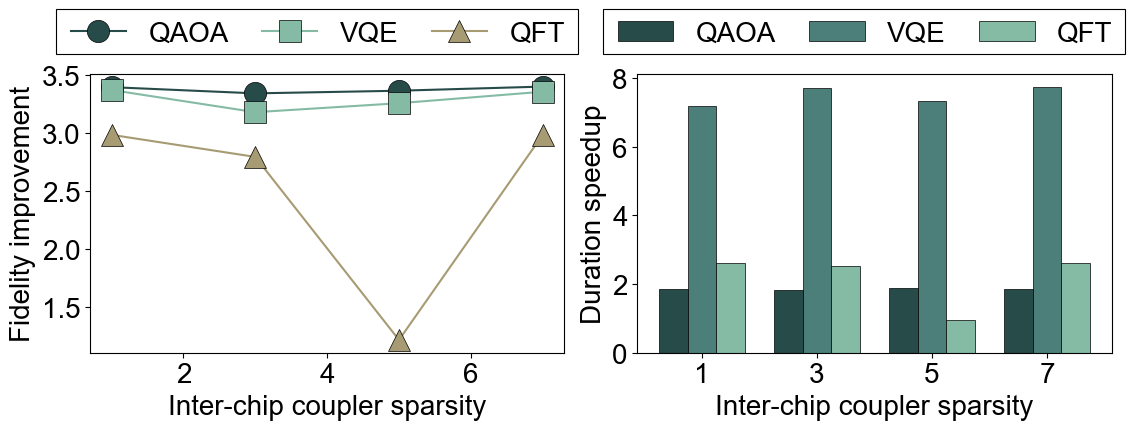

Average fide improve 3.054729407007203
Average fide improve 3.839097633233734


In [17]:
sparsity = [1, 3, 5, 7]

qaoa_depth_mech = [56450520, 55711800, 57567720, 56322840]
qaoa_fidelity_mech = [
    0.22496909311993782,
    0.22851907746810948,
    0.22685957715596025,
    0.2246550906747285,
]
qaoa_depth_qunoc = [3772174, 3785177, 3775146, 3760432]
qaoa_fidelity_qunoc = [
    0.7640517444588374,
    0.7638783446388439,
    0.7635019001566833,
    0.7641077865005196,
]

vqe_depth_mech = [55832640, 59054280, 57198360, 58461480]
vqe_fidelity_mech = [
    0.22235674038809247,
    0.23756006683213388,
    0.23127672396652824,
    0.22403914347783394,
]
vqe_depth_qunoc = [1129963, 1132877, 1150170, 1117348]
vqe_fidelity_qunoc = [
    0.7496676190800414,
    0.7555820833819589,
    0.7534724939033649,
    0.7520777331200809,
]

qft_depth_mech = [139524600, 135188040, 51402600, 139524600]
qft_fidelity_mech = [
    0.2623661315894859,
    0.2802163585184626,
    0.6429779416197564,
    0.26236625043426703,
]
qft_depth_qunoc = [5953605, 5953605, 5953605, 5953605]
qft_fidelity_qunoc = [
    0.7832629394497482,
    0.7832629394497482,
    0.7832629394497482,
    0.7832629394497482,
]

qaoa_depth_qunoc = [12269633.0, 12260719.0, 12241830.0, 12230674.0]
vqe_depth_qunoc = [3112388.0, 3073102.0, 3133395.0, 3029848.0]
qft_depth_qunoc = [21519547.0, 21519547.0, 21519547.0, 21519547.0]

import os
import numpy as np

def to_ms(lst, modify_const=1): 
    return [x / 1000000 * modify_const for x in lst]

import sys
sys.path.append("..")
from baseline.utils.utils import duration_modify_const
qaoa_depth_mech = to_ms(qaoa_depth_mech, duration_modify_const)
qaoa_depth_qunoc = to_ms(qaoa_depth_qunoc)
vqe_depth_mech = to_ms(vqe_depth_mech, duration_modify_const)
vqe_depth_qunoc = to_ms(vqe_depth_qunoc)
qft_depth_mech = to_ms(qft_depth_mech, duration_modify_const)
qft_depth_qunoc = to_ms(qft_depth_qunoc)

fide_improve_qaoa = np.array(qaoa_fidelity_qunoc) / np.array(qaoa_fidelity_mech)
fide_improve_vqe  = np.array(vqe_fidelity_qunoc) / np.array(vqe_fidelity_mech)
fide_improve_qft  = np.array(qft_fidelity_qunoc) / np.array(qft_fidelity_mech)

speedup_qaoa = np.array(qaoa_depth_mech) / np.array(qaoa_depth_qunoc)
speedup_vqe  = np.array(vqe_depth_mech)  / np.array(vqe_depth_qunoc)
speedup_qft  = np.array(qft_depth_mech)  / np.array(qft_depth_qunoc)


import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.legend_handler import HandlerTuple


color_list = ["#264B49", "#4C7F79", "#85BAA5", "#C0C2A6", "#A79B73"]
plt.rcParams["font.family"] = "arial"
plt.rcParams["font.size"] = 20

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# --- 子图1: 保真度差值 (折线图) ---
ax1.plot(sparsity, fide_improve_qaoa, "o-", markersize=16, markeredgecolor="black", markeredgewidth=0.5, label="QAOA", color=color_list[0])
ax1.plot(sparsity, fide_improve_vqe, "s-", markersize=16, markeredgecolor="black", markeredgewidth=0.5, label="VQE", color=color_list[2])
ax1.plot(sparsity, fide_improve_qft, "^-", markersize=16, markeredgecolor="black", markeredgewidth=0.5, label="QFT", color=color_list[4])

ax1.set_xlabel("Inter-chip coupler sparsity")
ax1.set_ylabel("Fidelity improvement")
# ax1.set_title("Fidelity optimization")
ax1.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.48, 1.28), frameon=False, columnspacing=1.2)

# --- 子图2: 深度加速比 (柱状图) ---
bar_width = 0.25
x = np.arange(len(sparsity))

ax2.bar(x - bar_width, speedup_qaoa, width=bar_width, label="QAOA", color=color_list[0], edgecolor="black", linewidth=0.5)
ax2.bar(x,             speedup_vqe,  width=bar_width, label="VQE", color=color_list[1], edgecolor="black", linewidth=0.5)
ax2.bar(x + bar_width, speedup_qft,  width=bar_width, label="QFT", color=color_list[2], edgecolor="black", linewidth=0.5)

ax2.set_xticks(x)
ax2.set_xticklabels(sparsity)
ax2.set_xlabel("Inter-chip coupler sparsity")
ax2.set_ylabel("Duration speedup")
# ax2.set_title("Depth optimization")
ax2.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.48, 1.28), frameon=False, columnspacing=1.2)

rect1 = mpatches.Rectangle(
    (0.063, 0.792),  # 左下角位置 (相对于 figure 坐标 0~1)
    width=0.435,    # 宽度
    height=0.09,  # 高度
    transform=fig.transFigure,  # 用 figure 的坐标系
    fill=False,                # 只画边框
    color="black",             # 边框颜色
    linewidth=0.8,             # 线宽
)
fig.patches.append(rect1)

rect2 = mpatches.Rectangle(
    (0.519, 0.792),  # 左下角位置 (相对于 figure 坐标 0~1)
    width=0.435,    # 宽度
    height=0.09,  # 高度
    transform=fig.transFigure,  # 用 figure 的坐标系
    fill=False,                # 只画边框
    color="black",             # 边框颜色
    linewidth=0.8,             # 线宽
)
fig.patches.append(rect2)

plt.tight_layout(w_pad=-0.8)
plt.savefig(os.path.join("./result/plot", "route_coupler_sparsity.svg"), bbox_inches="tight")
plt.savefig(os.path.join("./result/plot", "route_coupler_sparsity.pdf"), bbox_inches="tight")
plt.show()
plt.close()


print("Average fide improve", np.concatenate([fide_improve_qaoa, fide_improve_qft, fide_improve_vqe]).mean())
print("Average fide improve", np.concatenate([speedup_qaoa, speedup_qft, speedup_vqe]).mean())

## Coupler fidelity

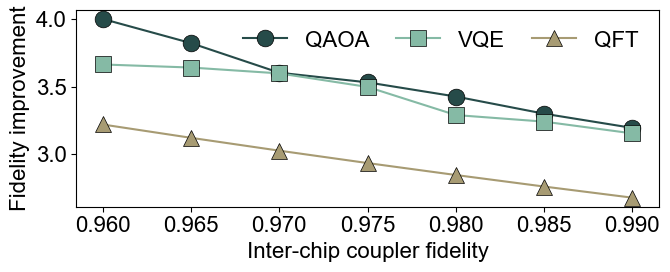

Average fide improve 3.31212307716988


In [25]:
inter_fidelity = [0.96,0.965, 0.97, 0.975,0.98,0.985, 0.99]

qaoa_depth_mech = [56277240, 55905600, 57205200, 55830360, 56046960, 56673960, 55793880]
qaoa_fidelity_mech = [
    0.19109102404569478,
    0.20008500613234148,
    0.212140000892673,
    0.21614807135461128,
    0.2229051117498562,
    0.23148830980489507,
    0.23914952130961542,
]
qaoa_depth_qunoc = [3727676, 3780555, 3784435, 3781336, 3806412, 3723527, 3801887]
qaoa_fidelity_qunoc = [
    0.7644115394502838,
    0.7646551401731652,
    0.7643145426869108,
    0.7633146582897251,
    0.7638529336594793,
    0.7639005387071457,
    0.7640240721819351,
]

vqe_depth_mech = [
    59225280,
    60415440,
    60324240,
    59733720,
    59323320,
    58044240,
    61658040,
]
vqe_fidelity_mech = [
    0.20500957533585948,
    0.20630008168518735,
    0.20942755041639535,
    0.21550939986156248,
    0.22878327697178896,
    0.2319521262192012,
    0.23854201047217977,
]
vqe_depth_qunoc = [
    1188425,
    1139617,
    1112174,
    1111849,
    1086654,
    1179695,
    1144003,
]
vqe_fidelity_qunoc = [
    0.7511038415105435,
    0.7511531029151918,
    0.753482315644351,
    0.7537878205290984,
    0.7526654976062238,
    0.7518290251214296,
    0.7524677690536378,
]

qft_depth_mech = [
    135188040,
    135188040,
    135188040,
    135188040,
    135188040,
    135188040,
    135188040,
]
qft_fidelity_mech = [
    0.24324284838312832,
    0.25091338882722647,
    0.2587842898749955,
    0.266859711704134,
    0.2751438788153233,
    0.28364108068924637,
    0.292355672446905,
]
qft_depth_qunoc = [
    5953605,
    5953605,
    5953605,
    5953605,
    5953605,
    5953605,
    5953605,
]
qft_fidelity_qunoc = [
    0.7832629394497482,
    0.7832629394497482,
    0.7832629394497482,
    0.7832629394497482,
    0.7832629394497482,
    0.7832629394497482,
    0.7832629394497482,
]

import os
import numpy as np

def to_ms(lst, modify_const=1): 
    return [x / 1000000 * modify_const for x in lst]

import sys
sys.path.append("..")
from baseline.utils.utils import duration_modify_const
qaoa_depth_mech = to_ms(qaoa_depth_mech, duration_modify_const)
qaoa_depth_qunoc = to_ms(qaoa_depth_qunoc)
vqe_depth_mech = to_ms(vqe_depth_mech, duration_modify_const)
vqe_depth_qunoc = to_ms(vqe_depth_qunoc)
qft_depth_mech = to_ms(qft_depth_mech, duration_modify_const)
qft_depth_qunoc = to_ms(qft_depth_qunoc)

fide_improve_qaoa = np.array(qaoa_fidelity_qunoc) / np.array(qaoa_fidelity_mech)
fide_improve_vqe  = np.array(vqe_fidelity_qunoc) / np.array(vqe_fidelity_mech)
fide_improve_qft  = np.array(qft_fidelity_qunoc) / np.array(qft_fidelity_mech)

speedup_qaoa = np.array(qaoa_depth_mech) / np.array(qaoa_depth_qunoc)
speedup_vqe  = np.array(vqe_depth_mech)  / np.array(vqe_depth_qunoc)
speedup_qft  = np.array(qft_depth_mech)  / np.array(qft_depth_qunoc)


import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from matplotlib.legend_handler import HandlerTuple


color_list = ["#264B49", "#4C7F79", "#85BAA5", "#C0C2A6", "#A79B73"]
plt.rcParams["font.family"] = "arial"
plt.rcParams["font.size"] = 16

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig, (ax1) = plt.subplots(1, 1, figsize=(7, 3))

# --- 子图1: 保真度差值 (折线图) ---
ax1.plot(inter_fidelity, fide_improve_qaoa, "o-", markersize=12, markeredgecolor="black", markeredgewidth=0.5, label="QAOA", color=color_list[0])
ax1.plot(inter_fidelity, fide_improve_vqe, "s-", markersize=12, markeredgecolor="black", markeredgewidth=0.5, label="VQE", color=color_list[2])
ax1.plot(inter_fidelity, fide_improve_qft, "^-", markersize=12, markeredgecolor="black", markeredgewidth=0.5, label="QFT", color=color_list[4])

ax1.set_xlabel("Inter-chip coupler fidelity")
ax1.set_ylabel("Fidelity improvement")
# ax1.set_title("Fidelity optimization")
ax1.legend(ncol=3, frameon=False, columnspacing=1.2)

# --- 子图2: 深度加速比 (柱状图) ---
# bar_width = 0.25
# x = np.arange(len(inter_fidelity))

# ax2.bar(x - bar_width, speedup_qaoa, width=bar_width, label="QAOA", color=color_list[0], edgecolor="black", linewidth=0.5)
# ax2.bar(x,             speedup_vqe,  width=bar_width, label="VQE", color=color_list[1], edgecolor="black", linewidth=0.5)
# ax2.bar(x + bar_width, speedup_qft,  width=bar_width, label="QFT", color=color_list[2], edgecolor="black", linewidth=0.5)

# ax2.set_xticks(x)
# ax2.set_xticklabels(inter_fidelity)
# ax2.set_xlabel("Inter-chip coupler fidelity")
# ax2.set_ylabel("Circuit duration speedup")
# # ax2.set_title("Depth optimization")
# ax2.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.44, 1.25), frameon=False, columnspacing=1.2)

# rect1 = mpatches.Rectangle(
#     (0.18, 0.85),  # 左下角位置 (相对于 figure 坐标 0~1)
#     width=0.7,    # 宽度
#     height=0.09,  # 高度
#     transform=fig.transFigure,  # 用 figure 的坐标系
#     fill=False,                # 只画边框
#     color="black",             # 边框颜色
#     linewidth=0.8,             # 线宽
# )
# fig.patches.append(rect1)

plt.tight_layout()
plt.savefig(os.path.join("./result/plot", "route_coupler_fidelity.svg"), bbox_inches="tight")
plt.savefig(os.path.join("./result/plot", "route_coupler_fidelity.pdf"), bbox_inches="tight")
plt.show()
plt.close()

print("Average fide improve", np.concatenate([fide_improve_qaoa, fide_improve_qft, fide_improve_vqe]).mean())